# GiftLane — Customers Like You

## Project Objective

Build a product recommendation system and a customer-segmentation map using the UCI Online Retail II dataset.

The project will be completed individually, with responsibility for both Data Engineering (DE) and Machine Learning Engineering (ML).

## Workflow

1. Profile the raw dataset.
2. Clean and document the transaction data.
3. Create a time-based training and test split.
4. Build and report the sparse customer–product matrix.
5. Compare PCA and Truncated SVD.
6. Generate and evaluate product recommendations.
7. Visualize customer segments.
8. Prepare the stakeholder memo and presentation.

## Project Rules

- R1: Record and justify each decision.
- R2: Hold out test purchases before fitting the model.
- R3: Compare against the 10 best-selling products.
- R4: Do not expose customer IDs in the memo, slides, or figures.
- R5: Keep work in the shared Git repository, with individual contributions recorded.
- R6: Ensure reproducibility with fixed random seeds, a requirements file, and a reproducible matrix-building process.

In [1]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nExisting files and folders:")
for item in sorted(Path.cwd().iterdir()):
    print(item.name)

print("\nRaw-data folder exists:", Path("data/raw").is_dir())
print(
    "Dataset file exists:",
    Path("data/raw/online_retail_II.xlsx").is_file()
)

Current working directory:
C:\Users\harsh\giftlane-project\notebooks

Existing files and folders:
.ipynb_checkpoints
analysis.ipynb

Raw-data folder exists: False
Dataset file exists: False


## DE1 — Raw Data Profiling

### Objective

Load the sheet of the Online Retail II workbook and inspect the raw data before cleaning.

### Checks

- Identify the available sheet.
- Record the row count of each sheet and the combined dataset.
- Inspect column names and data types.
- Calculate missing values and missing-value percentages for each column.

No cleaning or filtering is performed in this step.

In [3]:

from pathlib import Path

print("Notebook's current working directory:")
print(Path.cwd())

print("\nFiles and folders in the current directory:")
for item in Path.cwd().iterdir():
    print(item.name)


Notebook's current working directory:
C:\Users\harsh\giftlane-project\notebooks

Files and folders in the current directory:
.ipynb_checkpoints
analysis.ipynb


In [4]:

from pathlib import Path

project_root = Path.cwd().parent

print("Project root:", project_root)
print("\nItems in project root:")

for item in project_root.iterdir():
    print(item.name)


Project root: C:\Users\harsh\giftlane-project

Items in project root:
.ipynb_checkpoints
data
notebooks
src


In [5]:

from pathlib import Path

project_root = Path.cwd().parent

for file in project_root.rglob("*"):
    if file.is_file() and "online_retail" in file.name.lower():
        print(file)


C:\Users\harsh\giftlane-project\data\raw\online_retail_II.xlsx


In [6]:

import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent
file_path = project_root / "data" / "raw" / "online_retail_II.xlsx"

print("File exists:", file_path.is_file())
print("File path:", file_path)

excel_file = pd.ExcelFile(file_path)

print("\nSheet names:", excel_file.sheet_names)
print("Number of sheets:", len(excel_file.sheet_names))


File exists: True
File path: C:\Users\harsh\giftlane-project\data\raw\online_retail_II.xlsx

Sheet names: ['Year 2009-2010', 'Year 2010-2011']
Number of sheets: 2


## DE1: Load and Profile the Raw Dataset

**Objective:** Load both worksheets from the Online Retail II Excel workbook, inspect column names and data types, report row counts, and identify missing values in each column.

The two worksheets are `Year 2009-2010` and `Year 2010-2011`. Their data will be combined into a single DataFrame for the initial data profile.

In [7]:
import pandas as pd
from pathlib import Path

# Locate the raw Excel workbook
PROJECT_ROOT = Path.cwd().parent
RAW_FILE = PROJECT_ROOT / "data" / "raw" / "online_retail_II.xlsx"

# Load both worksheets
sheets = pd.read_excel(RAW_FILE, sheet_name=None)

# Report worksheet names and row counts
print("Worksheet names:", list(sheets.keys()))

for sheet_name, sheet_df in sheets.items():
    print(f"{sheet_name}: {len(sheet_df):,} rows")

# Combine both worksheets
df_raw = pd.concat(sheets.values(), ignore_index=True)

print("\nCombined dataset row count:", f"{len(df_raw):,}")
print("Combined dataset shape:", df_raw.shape)


Worksheet names: ['Year 2009-2010', 'Year 2010-2011']
Year 2009-2010: 525,461 rows
Year 2010-2011: 541,910 rows

Combined dataset row count: 1,067,371
Combined dataset shape: (1067371, 8)


In [8]:
#Check column names and data types
print("Column names:")
print(df_raw.columns.tolist())

print("\nColumn data types:")
print(df_raw.dtypes)


Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Column data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object


In [12]:
missing_values = df_raw.isnull().sum()

print("Missing values per column:")
display(missing_values.to_frame(name="Missing Values"))


Missing values per column:


,Missing Values
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


### DE1: Missing Values per Column

The missing-value analysis identified missing entries in two columns:

- **Description:** 4,382 missing values.
- **Customer ID:** 243,007 missing values.

The remaining columns:Invoice, StockCode, Quantity, InvoiceDate, Price, and Country contain no missing values.

These results document the missing values in the raw dataset before cleaning. No rows have been removed or modified as part of this analysis.

In [13]:
print("Raw dataset memory usage:")

raw_memory_bytes = df_raw.memory_usage(deep=True).sum()
raw_memory_mb = raw_memory_bytes / (1024 ** 2)

print(f"{raw_memory_mb:.2f} MB")

Raw dataset memory usage:
207.32 MB


## DE 2: Data Cleaning

### Objective
The objective of this stage is to clean the Online Retail II dataset by removing invalid transactions and incomplete records so that the data is suitable for building a customer–product purchase matrix and training the recommendation model.

### Approach
A working copy of the raw dataset, `df_clean`, is used for cleaning while `df_raw` remains unchanged. This preserves the original data for comparison and allows the cleaning process to be reproduced.

The following rules are applied sequentially:

1. **Remove cancellation invoices:** Exclude invoices whose invoice number begins with `C` to avoid treating cancelled transactions as purchases.
2. **Remove non-positive quantities:** Exclude rows where `Quantity` is zero or negative.
3. **Remove non-positive prices:** Exclude rows where `Price` is zero or negative.
4. **Remove non-product stock codes:** Exclude known non-product codes such as `POST`, `M`, `D`, and `BANK CHARGES`.
5. **Remove missing customer IDs:** Exclude rows without a `Customer ID`, because customer-level recommendations require identifiable customer records.
6. **Remove missing product descriptions:** Exclude rows with missing `Description` values to improve product interpretability.

### Cleaning Log
The number of rows removed by each rule and the number remaining after each step are recorded in a cleaning log. This provides an auditable record of the data-cleaning process.

### Validation
After cleaning, the dataset is checked for remaining cancellation invoices, non-positive quantities, non-positive prices, and missing customer IDs. The final dataset shape and memory usage are also recorded.

### Outcome
The resulting `df_clean` dataset is used as the cleaned input for DE 3, where the data is split chronologically into training and testing periods. The original `df_raw` dataset remains unchanged.

In [15]:
df_clean = df_raw.copy()

print("Original dataset shape(df_raw):", df_raw.shape)
print("Working dataset shape(df_clean):", df_clean.shape)

Original dataset shape(df_raw): (1067371, 8)
Working dataset shape(df_clean): (1067371, 8)


In [16]:
print("Columns in dataset:")
print(df_clean.columns.tolist())

Columns in dataset:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [24]:
# DE 2: Data Cleaning

# Start from the original dataset every time
df_clean = df_raw.copy()
cleaning_log = []

print("Original dataset shape:", df_raw.shape)

# Rule 1: Remove cancellation invoices
before = len(df_clean)
df_clean = df_clean[
    ~df_clean["Invoice"].astype(str).str.startswith("C", na=False)
].copy()

cleaning_log.append({
    "Rule": "Cancellation invoices",
    "Rows Removed": before - len(df_clean),
    "Rows Remaining": len(df_clean)
})

# Rule 2: Remove non-positive quantities
before = len(df_clean)
df_clean = df_clean[df_clean["Quantity"] > 0].copy()

cleaning_log.append({
    "Rule": "Non-positive quantity",
    "Rows Removed": before - len(df_clean),
    "Rows Remaining": len(df_clean)
})

# Rule 3: Remove non-positive prices
before = len(df_clean)
df_clean = df_clean[df_clean["Price"] > 0].copy()

cleaning_log.append({
    "Rule": "Non-positive price",
    "Rows Removed": before - len(df_clean),
    "Rows Remaining": len(df_clean)
})

# Rule 4: Remove known non-product stock codes
non_product_codes = ["POST", "M", "D", "BANK CHARGES"]

before = len(df_clean)
df_clean = df_clean[
    ~df_clean["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
    .isin(non_product_codes)
].copy()

cleaning_log.append({
    "Rule": "Non-product stock codes",
    "Rows Removed": before - len(df_clean),
    "Rows Remaining": len(df_clean)
})

# Rule 5: Remove rows without Customer ID
before = len(df_clean)
df_clean = df_clean[df_clean["Customer ID"].notna()].copy()

cleaning_log.append({
    "Rule": "Missing Customer ID",
    "Rows Removed": before - len(df_clean),
    "Rows Remaining": len(df_clean)
})

# Display the cleaning log
cleaning_log_df = pd.DataFrame(cleaning_log)
display(cleaning_log_df)

print("Final cleaned dataset shape:", df_clean.shape)


Original dataset shape: (1067371, 8)


,Rule,Rows Removed,Rows Remaining
0,Cancellation invoices,19494,1047877
1,Non-positive quantity,3457,1044420
2,Non-positive price,2750,1041670
3,Non-product stock codes,2807,1038863
4,Missing Customer ID,235898,802965


Final cleaned dataset shape: (802965, 8)


In [25]:
print("Missing Customer IDs:", df_clean["Customer ID"].isna().sum())
print("Non-positive quantities:", (df_clean["Quantity"] <= 0).sum())
print("Non-positive prices:", (df_clean["Price"] <= 0).sum())

print(
    "Cancellation invoices remaining:",
    df_clean["Invoice"].astype(str).str.startswith("C").sum()
)

print("\nCleaned dataset shape:", df_clean.shape)

Missing Customer IDs: 0
Non-positive quantities: 0
Non-positive prices: 0
Cancellation invoices remaining: 0

Cleaned dataset shape: (802965, 8)



## DE3: Temporal Train/Test Split

### Objective
Split the cleaned transaction dataset chronologically, using the last two months as the test period. Identify purchases of products that each test-period customer had never purchased during the training period, following requirement R2.

### Methodology
1. Inspect the transaction date range and ensure `InvoiceDate` is in a valid datetime format.
2. Define the final two calendar months of the dataset as the test period.
3. Assign transactions before the test period to the training dataset (`df_train`) and transactions within the test period to the test dataset (`df_test`).
4. For each customer in the test dataset, compare their test-period products against the products they purchased during training.
5. Identify previously unseen customer–product purchases as evaluation targets.
6. Keep the training and test datasets separate to prevent data leakage. Any PCA, SVD, or recommendation model must be fitted using training data only.

### Expected Outputs
- Training and test date ranges
- Number of rows in each split
- Number of unique customers and products in each split
- Previously unseen customer–product purchases identified for evaluation

### Data Leakage Prevention
The test period is held out from model fitting. Product history used to identify unseen purchases is calculated from the training dataset only. The original cleaned dataset remains unchanged.

In [26]:
print("InvoiceDate data type:", df_clean["InvoiceDate"].dtype)
print("Earliest transaction:", df_clean["InvoiceDate"].min())
print("Latest transaction:", df_clean["InvoiceDate"].max())
print("Missing transaction dates:", df_clean["InvoiceDate"].isna().sum())

InvoiceDate data type: datetime64[us]
Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2011-12-09 12:50:00
Missing transaction dates: 0


In [27]:
# DE3: Temporal Train/Test Split
import pandas as pd

# The final two months by elapsed time, relative to the latest transaction
test_end = df_clean["InvoiceDate"].max()
test_start = test_end - pd.DateOffset(months=2)

# Split chronologically
df_train = df_clean[df_clean["InvoiceDate"] < test_start].copy()
df_test = df_clean[df_clean["InvoiceDate"] >= test_start].copy()

print("Test period starts:", test_start)
print("Test period ends:", test_end)

print("\nTraining rows:", len(df_train))
print("Test rows:", len(df_test))

print("\nTraining date range:")
print(df_train["InvoiceDate"].min(), "to", df_train["InvoiceDate"].max())

print("\nTest date range:")
print(df_test["InvoiceDate"].min(), "to", df_test["InvoiceDate"].max())


Test period starts: 2011-10-09 12:50:00
Test period ends: 2011-12-09 12:50:00

Training rows: 684357
Test rows: 118608

Training date range:
2009-12-01 07:45:00 to 2011-10-09 12:49:00

Test date range:
2011-10-09 12:59:00 to 2011-12-09 12:50:00


In [28]:

# DE3: Identify unseen customer-product purchases (R2)

# Unique customer-product pairs purchased during training
train_pairs = df_train[["Customer ID", "StockCode"]].drop_duplicates()

# Unique customer-product pairs purchased during testing
test_pairs = df_test[["Customer ID", "StockCode"]].drop_duplicates()

# Find test pairs absent from training
unseen_pairs = test_pairs.merge(
    train_pairs,
    on=["Customer ID", "StockCode"],
    how="left",
    indicator=True
)

unseen_pairs = unseen_pairs[
    unseen_pairs["_merge"] == "left_only"
].drop(columns="_merge")

print("Unique customer-product pairs in training:", len(train_pairs))
print("Unique customer-product pairs in test:", len(test_pairs))
print("Unseen customer-product pairs in test:", len(unseen_pairs))
print("Unique customers with unseen products:",
      unseen_pairs["Customer ID"].nunique())
print("Unique unseen products:", unseen_pairs["StockCode"].nunique())


Unique customer-product pairs in training: 417809
Unique customer-product pairs in test: 95027
Unseen customer-product pairs in test: 63256
Unique customers with unseen products: 2308
Unique unseen products: 2850


### DE3: Temporal Train/Test Split and Unseen Products

The cleaned dataset was split chronologically using a rolling two-month test period, defined relative to the latest transaction date. Transactions before the cutoff were assigned to the training dataset, while transactions from the cutoff onward were assigned to the test dataset.

To satisfy requirement R2, unique customer–product combinations in the test period were compared with those observed during training. Test combinations absent from the training history were identified as unseen customer–product pairs and retained as candidate evaluation targets.

**Results:**
- Unique customer–product pairs in training: 417,809
- Unique customer–product pairs in testing: 95,027
- Unseen customer–product pairs in testing: 63,256
- Customers with at least one unseen product: 2,308
- Unique unseen products: 2,850

Approximately 66.56% of the unique customer–product pairs in the test period were absent from the training history. These unseen pairs can be used to evaluate the model's ability to recommend products not previously purchased by a customer.

To prevent data leakage, the training data must be used exclusively for fitting preprocessing steps and recommendation models. The test data and unseen pairs must remain held out for evaluation.

## DE4: Build the Sparse Customer × Product Matrix

### Objective
Construct a sparse customer–product matrix using training transactions only, as required by the project.

### Methodology
1. Count the number of distinct training customers who purchased each product.
2. Retain products purchased by at least 10 distinct customers.
3. Aggregate quantities for each customer–product combination.
4. Transform each aggregated quantity using `log(1 + total quantity)` to reduce the influence of unusually large purchases.
5. Assign each customer to a matrix row and each product to a matrix column using index maps.
6. Build the matrix in Compressed Sparse Row (CSR) format.
7. Save the sparse matrix as an `.npz` file and save the customer and product index maps.

### Data Leakage Prevention
Only `df_train` is used to construct the matrix. The held-out test data is not used to calculate product popularity, select products, or fit a model.

### Expected Outputs
- Sparse customer–product matrix
- Customer index map
- Product index map
- Matrix shape and number of nonzero entries for DE5

In [30]:

# DE 4: Build the Sparse Customer x Product Matrix

import numpy as np
import pandas as pd
import scipy.sparse as sp

# 1. Confirm that training data is available
print("Training dataset shape:", df_train.shape)

# 2. Create a copy and standardize product-code data types
train_de4 = df_train.copy()
train_de4["StockCode"] = train_de4["StockCode"].astype(str)

# 3. Count distinct training customers for each product
product_customer_counts = (
    train_de4.groupby("StockCode")["Customer ID"].nunique()
)

# 4. Keep products bought by at least 10 distinct customers
min_customers_per_product = 10

kept_products = product_customer_counts[
    product_customer_counts >= min_customers_per_product
].index

train_filtered = train_de4[
    train_de4["StockCode"].isin(kept_products)
].copy()

print("Products before filtering:", train_de4["StockCode"].nunique())
print("Products retained:", len(kept_products))
print(
    "Products filtered out:",
    train_de4["StockCode"].nunique() - len(kept_products)
)

# 5. Aggregate quantity for each customer-product pair
customer_product = (
    train_filtered
    .groupby(["Customer ID", "StockCode"], as_index=False)["Quantity"]
    .sum()
)

# 6. Calculate log-transformed purchase values
customer_product["PurchaseValue"] = np.log1p(
    customer_product["Quantity"]
)

# 7. Create index maps
customers = sorted(customer_product["Customer ID"].unique())
products = sorted(customer_product["StockCode"].unique())

customer_to_idx = {
    customer: i for i, customer in enumerate(customers)
}
product_to_idx = {
    product: j for j, product in enumerate(products)
}

print("Number of customers:", len(customers))
print("Number of products:", len(products))

# 8. Map customer-product pairs to matrix coordinates
rows = customer_product["Customer ID"].map(customer_to_idx).to_numpy()
cols = customer_product["StockCode"].map(product_to_idx).to_numpy()
values = customer_product["PurchaseValue"].to_numpy(dtype=np.float64)

# 9. Build the sparse CSR matrix
A = sp.csr_matrix(
    (values, (rows, cols)),
    shape=(len(customers), len(products))
)

A.sum_duplicates()
A.eliminate_zeros()

print("\nSparse matrix constructed successfully.")
print("Matrix shape:", A.shape)
print("Nonzero entries:", A.nnz)
print("Number of customers:", len(customers))
print("Number of products:", len(products))


Training dataset shape: (684357, 8)
Products before filtering: 4537
Products retained: 3690
Products filtered out: 847
Number of customers: 5483
Number of products: 3690

Sparse matrix constructed successfully.
Matrix shape: (5483, 3690)
Nonzero entries: 414008
Number of customers: 5483
Number of products: 3690


In [31]:

# DE 4: Save the sparse matrix and index maps

from pathlib import Path
import pandas as pd
import scipy.sparse as sp

# Create the output directory
output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save the sparse customer-product matrix
sp.save_npz(
    output_dir / "customer_product_train.npz",
    A
)

# 2. Save the customer index map (keep private)
customer_map_df = pd.DataFrame({
    "Customer ID": customers,
    "Matrix Index": range(len(customers))
})

customer_map_df.to_csv(
    output_dir / "customer_index_map.csv",
    index=False
)

# 3. Save the product index map
product_map_df = pd.DataFrame({
    "StockCode": products,
    "Matrix Index": range(len(products))
})

product_map_df.to_csv(
    output_dir / "product_index_map.csv",
    index=False
)

# 4. Confirm saved files
print("DE4 outputs saved successfully.")
print("Matrix shape:", A.shape)
print("Nonzero entries:", A.nnz)
print("Saved files:")

for file_path in sorted(output_dir.glob("*")):
    print(f"- {file_path.name} ({file_path.stat().st_size / 1024:.2f} KB)")


DE4 outputs saved successfully.
Matrix shape: (5483, 3690)
Nonzero entries: 414008
Saved files:
- customer_index_map.csv (73.90 KB)
- customer_product_train.npz (1030.56 KB)
- product_index_map.csv (42.97 KB)


In [35]:
print("Products before filtering:", train_de4["StockCode"].nunique())
print("Products retained:", len(kept_products))
print("Products filtered out:",
      train_de4["StockCode"].nunique() - len(kept_products))

Products before filtering: 4537
Products retained: 3690
Products filtered out: 847


## DE5: Sparse Matrix Report

### Objective
Analyze the customer-product matrix created in DE4 by reporting its shape, number of non-zero entries, sparsity percentage, and memory usage compared with an equivalent dense matrix.

### Matrix Report
The customer-product matrix was stored in Compressed Sparse Row (CSR) format. The matrix was constructed using training data only, with `log(1 + total quantity)` as the purchase value and a product filter that retained products purchased by at least 10 distinct customers.

The following metrics were calculated:
- **Matrix shape:** 5,483 customers × 3,690 products.
- **Number of non-zero entries:** 414,008.
- **Total possible entries:** 20,228,670.
- **Sparsity:** Approximately 97.95% of the matrix entries are zero.
- **Dense memory usage:** Approximately 154.45 MiB for an equivalent `float64` matrix.
- **Sparse memory usage:** Calculated from the CSR matrix's data, indices, and row-pointer arrays.

In [36]:

# DE5: Matrix Report

import numpy as np

# 1. Matrix shape
rows, columns = A.shape

# 2. Number of non-zero entries
nonzero_entries = A.nnz

# 3. Sparsity percentage
total_entries = rows * columns
sparsity_percent = (
    (total_entries - nonzero_entries) / total_entries
) * 100

# 4. Memory usage: sparse vs dense
sparse_bytes = (
    A.data.nbytes
    + A.indices.nbytes
    + A.indptr.nbytes
)

dense_bytes = total_entries * np.dtype(np.float64).itemsize

sparse_mib = sparse_bytes / (1024 ** 2)
dense_mib = dense_bytes / (1024 ** 2)

memory_saved_percent = (1 - sparse_bytes / dense_bytes) * 100

# Display report
print("DE5: MATRIX REPORT")
print("-" * 40)
print(f"Matrix shape: {rows:,} x {columns:,}")
print(f"Number of non-zeros: {nonzero_entries:,}")
print(f"Sparsity: {sparsity_percent:.2f}%")
print(f"Sparse memory: {sparse_mib:.2f} MiB")
print(f"Dense memory: {dense_mib:.2f} MiB")
print(f"Memory saved: {memory_saved_percent:.2f}%")


DE5: MATRIX REPORT
----------------------------------------
Matrix shape: 5,483 x 3,690
Number of non-zeros: 414,008
Sparsity: 97.95%
Sparse memory: 4.76 MiB
Dense memory: 154.36 MiB
Memory saved: 96.92%


### Sparsity Calculation

Sparsity was calculated as the percentage of zero entries in the matrix.

$$
\text{Sparsity (\%)} =
\frac{\text{Total Entries} - \text{Non-zero Entries}}
{\text{Total Entries}} \times 100
$$

For our matrix:

$$
\text{Sparsity (\%)} =
\frac{20,228,670 - 414,008}{20,228,670}
\times 100
\approx 97.95\%
$$

### Memory Comparison
The sparse matrix uses 4.76 MiB, compared with 154.36 MiB for an equivalent dense matrix. Using sparse storage saves approximately 96.92% of the matrix storage memory.

### Conclusion
The customer-product matrix is highly sparse because most customers purchase only a small fraction of the available products. CSR storage avoids explicitly storing all zero entries, substantially reducing memory requirements. This makes the matrix more memory-efficient for subsequent recommendation-modeling tasks.

## ML1: Method Selection — Truncated SVD

### Objective
Select a dimensionality-reduction method for GiftLane's sparse customer-product purchase matrix before fitting any model.

### Selected Method
**Truncated Singular Value Decomposition (SVD)** is selected as the primary method.

### Justification
The customer-product matrix contains 5,483 customers, 3,690 products, and 414,008 non-zero entries. Approximately 97.95% of its entries are zero.

Truncated SVD is suitable for this matrix because it works directly with sparse data without requiring the matrix to be centered. This avoids the need to convert the sparse matrix into a dense matrix before decomposition.

Truncated SVD reduces the original customer-product matrix to a lower-dimensional representation. The resulting customer and product factors can be used to calculate product similarities and generate personalized product recommendations.

### Limitations and Comparison Plan
Reducing the number of dimensions may discard useful information from the original purchase matrix. This could affect recommendation quality. Therefore, different numbers of components will be evaluated using reconstruction error and recommendation performance.

As required by ML5, PCA will also be evaluated using the same training matrix and the specified component counts. Fit time, memory usage, model size, reconstruction quality, and hit rate at 10 will be compared.

### Decision
Truncated SVD is selected as the primary method because it is compatible with the sparse customer-product matrix and provides useful latent representations for product recommendations. The final number of components will be selected based on experimental results rather than assumed in advance.

## ML2: Truncated SVD — Component Selection

### Objective
Evaluate Truncated SVD using 10, 20, 50, 100, and 200 components to determine how the number of components affects reconstruction error.

### Method
The model will be fitted using the training customer-product matrix created in DE4. A fixed random seed of 42 will be used to support reproducibility. The test dataset will not be used to fit the model.

### Evaluation
For each component count, the experiment will record model fitting time and relative reconstruction error. A plot of reconstruction error against the number of components will help identify how much information is retained as the number of components increases.

### Selection Criteria
The component count will be chosen based on the reconstruction-error trend and will be evaluated further using recommendation performance in subsequent tasks.

In [38]:

# ML2: Check the matrix before fitting Truncated SVD

print("Matrix shape:", A.shape)
print("Non-zero entries:", A.nnz)
print("Matrix type:", type(A).__name__)
print("Data type:", A.dtype)


Matrix shape: (5483, 3690)
Non-zero entries: 414008
Matrix type: csr_matrix
Data type: float64


In [39]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

# Required component counts
k_values = [10, 20, 50, 100, 200]

# Store results and fitted models
svd_results = []
svd_models = {}

# Squared Frobenius norm of the original sparse matrix
original_norm_squared = np.sum(A.data ** 2)

for k in k_values:
    print(f"Fitting Truncated SVD with k={k}...")

    svd = TruncatedSVD(
        n_components=k,
        random_state=42
    )

    start_time = time.perf_counter()
    Z = svd.fit_transform(A)
    fit_time = time.perf_counter() - start_time

    # Calculate reconstruction error without creating A_hat
    # A_hat = Z @ svd.components_
    projected = A @ svd.components_.T

    reconstructed_norm_squared = np.sum(
        (Z.T @ Z) * (svd.components_ @ svd.components_.T).T
    )

    cross_product = np.sum(Z * projected)

    residual_squared = (
        original_norm_squared
        + reconstructed_norm_squared
        - 2 * cross_product
    )

    # Protect against tiny negative values from floating-point rounding
    residual_squared = max(residual_squared, 0.0)

    relative_error = np.sqrt(
        residual_squared / original_norm_squared
    )

    svd_results.append({
        "Components (k)": k,
        "Fit Time (seconds)": fit_time,
        "Relative Reconstruction Error": relative_error,
        "Explained Variance Ratio": svd.explained_variance_ratio_.sum()
    })

    svd_models[k] = svd

    print(
        f"  Fit time: {fit_time:.2f} seconds | "
        f"Relative reconstruction error: {relative_error:.4f}"
    )

# Display the results
svd_results_df = pd.DataFrame(svd_results)

print("\nML2: Truncated SVD Results")
display(svd_results_df.round(4))


Fitting Truncated SVD with k=10...
  Fit time: 0.13 seconds | Relative reconstruction error: 0.8761
Fitting Truncated SVD with k=20...
  Fit time: 0.13 seconds | Relative reconstruction error: 0.8459
Fitting Truncated SVD with k=50...
  Fit time: 0.95 seconds | Relative reconstruction error: 0.7897
Fitting Truncated SVD with k=100...
  Fit time: 1.63 seconds | Relative reconstruction error: 0.7279
Fitting Truncated SVD with k=200...
  Fit time: 2.67 seconds | Relative reconstruction error: 0.6396

ML2: Truncated SVD Results


,Components (k),Fit Time (seconds),Relative Reconstruction Error,Explained Variance Ratio
0,10,0.1266,0.8761,0.1983
1,20,0.1310,0.8459,0.2525
2,50,0.9503,0.7897,0.3484
3,100,1.6323,0.7279,0.4463
4,200,2.6684,0.6396,0.5725


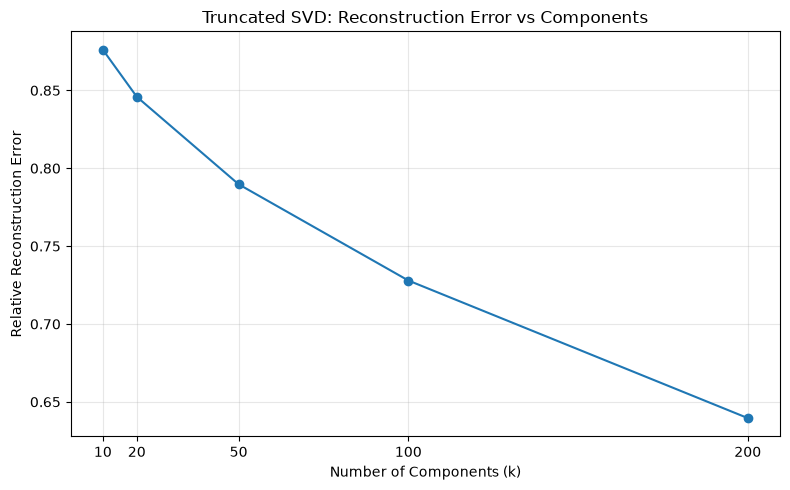

In [40]:

# ML2: Plot relative reconstruction error against component count

plt.figure(figsize=(8, 5))

plt.plot(
    svd_results_df["Components (k)"],
    svd_results_df["Relative Reconstruction Error"],
    marker="o"
)

plt.xlabel("Number of Components (k)")
plt.ylabel("Relative Reconstruction Error")
plt.title("Truncated SVD: Reconstruction Error vs Components")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## ML3: Product Similarity and Customer Recommendation Scores

### Objective
Use the trained Truncated SVD model to identify similar products and calculate recommendation scores for customers.

### Method
The 200-component Truncated SVD model will initially be used to obtain lower-dimensional product representations. Cosine similarity will be calculated between product factor vectors to identify the top 10 most similar products for each product.

Customer recommendation scores will be calculated by multiplying the customer latent factors by the product factor matrix. Products already purchased by a customer in the training data will be excluded from that customer's recommendations.

### Expected Output
- Top 10 similar products for each product.
- Customer-product recommendation scores.
- Top 10 recommended products for selected customers.

### Limitations
Recommendations are based on historical purchase patterns represented by the training matrix. Product similarity and recommendation quality will be evaluated further using held-out purchases in ML4.

In [41]:
# ML3: Check the fitted SVD model
svd_200 = svd_models[200]

print("Customer factors shape:", svd_200.transform(A).shape)
print("Product factors shape:", svd_200.components_.shape)
print("Number of products:", len(products))
print("Number of customers:", len(customers))

Customer factors shape: (5483, 200)
Product factors shape: (200, 3690)
Number of products: 3690
Number of customers: 5483


In [42]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

# Product factor vectors: one row per product
product_factors = svd_200.components_.T

# Calculate cosine similarity between all products
product_similarity = cosine_similarity(product_factors)

# Exclude each product's similarity to itself
np.fill_diagonal(product_similarity, -np.inf)

# Find the top 10 most similar products for every product
top_n = 10
top_similar_indices = np.argsort(
    -product_similarity, axis=1
)[:, :top_n]

# Convert matrix indices back to StockCode values
similar_products_rows = []

for product_idx, similar_indices in enumerate(top_similar_indices):
    source_product = products[product_idx]

    for rank, similar_idx in enumerate(similar_indices, start=1):
        similar_products_rows.append({
            "Product": source_product,
            "Similar Product": products[similar_idx],
            "Similarity Score": product_similarity[product_idx, similar_idx],
            "Rank": rank
        })

similar_products_df = pd.DataFrame(similar_products_rows)

print("Product similarity calculation complete.")
print("Number of product-similarity rows:", len(similar_products_df))
display(similar_products_df.head(20).round(4))

Product similarity calculation complete.
Number of product-similarity rows: 36900


,Product,Similar Product,Similarity Score,Rank
0,10002,21786,0.2805,1
1,10002,23509,0.2704,2
2,10002,21788,0.2586,3
3,10002,22580,0.2569,4
4,10002,21312,0.2490,5
5,10002,21789,0.2451,6
6,10002,20783,0.2436,7
7,10002,22991,0.2422,8
8,10002,23084,0.2418,9
9,10002,22992,0.2405,10


In [43]:

# ML3: Calculate customer-product recommendation scores

# Customer latent factors: customers x components
customer_factors = svd_200.transform(A)

# Product latent factors: components x products
product_factors = svd_200.components_

# Predicted customer-product preference scores
recommendation_scores = customer_factors @ product_factors

print("Recommendation score matrix shape:", recommendation_scores.shape)
print("Number of customers:", recommendation_scores.shape[0])
print("Number of products:", recommendation_scores.shape[1])


Recommendation score matrix shape: (5483, 3690)
Number of customers: 5483
Number of products: 3690


In [44]:

# ML3: Generate top 10 recommendations for one customer

# Select the first customer in the matrix
customer_idx = 0
customer_id = customers[customer_idx]

# Get this customer's recommendation scores
scores = recommendation_scores[customer_idx].copy()

# Exclude products already purchased in the training matrix
purchased_product_indices = A[customer_idx].indices
scores[purchased_product_indices] = -np.inf

# Select the 10 highest-scoring remaining products
top_indices = np.argsort(-scores)[:10]

recommendations_df = pd.DataFrame({
    "Rank": range(1, 11),
    "Recommended Product": [products[i] for i in top_indices],
    "Recommendation Score": scores[top_indices]
})

print("Top 10 recommendations generated.")
display(recommendations_df.round(4))

Top 10 recommendations generated.


,Rank,Recommended Product,Recommendation Score
0,1,23167,0.7527
1,2,23165,0.7465
2,3,22993,0.4767
3,4,48194,0.4752
4,5,85014B,0.4359
5,6,23284,0.4192
6,7,85014A,0.4056
7,8,48184,0.3971
8,9,48129,0.2796
9,10,23301,0.2629


In [45]:

# Verify that recommended products were not previously purchased

purchased_indices = set(A[customer_idx].indices)
recommended_indices = set(top_indices)

overlap = purchased_indices.intersection(recommended_indices)

print("Number of recommendations:", len(top_indices))
print("Duplicate recommendations:", len(recommended_indices) != len(top_indices))
print("Previously purchased products recommended:", len(overlap))

if len(top_indices) == 10 and len(overlap) == 0:
    print("Validation passed: all 10 recommendations are unique and unseen in training.")
else:
    print("Validation needs review.")


Number of recommendations: 10
Duplicate recommendations: False
Previously purchased products recommended: 0
Validation passed: all 10 recommendations are unique and unseen in training.


### ML3 Results and Conclusion

The 200-component Truncated SVD model was used to calculate cosine similarities between product factor vectors. The resulting similarity table contains 36,900 rows, representing the top 10 similar products for each of the 3,690 products.

Customer-product recommendation scores were calculated by multiplying customer latent factors by product latent factors. The recommendation process excludes products already purchased by each customer in the training matrix.

A sample set of 10 recommendations was generated for validation. Recommendation quality will be evaluated against held-out purchases and the top-10 best-selling product baseline in ML4.

## ML4: Recommendation Evaluation

### Objective
Evaluate the Truncated SVD recommendation model using held-out purchases and compare its performance against a baseline that recommends the 10 best-selling products.

### Evaluation Method
The model will be evaluated on purchases in the test period that were not present in the training customer-product pairs. Only customers with training history and eligible products retained in the DE4 matrix will be evaluated.

For each eligible customer, the model will recommend up to 10 products that they have not purchased in the training data. The same eligibility rules will be applied to the best-seller baseline.

### Evaluation Metric
Hit Rate@10 is the proportion of evaluated customers for whom at least one held-out target product appears in the top 10 recommendations.

### Runtime Measurement
The time required to generate recommendations will be measured to assess the feasibility of a nightly recommendation job.

### Data Leakage Prevention
The SVD model and best-seller baseline will be fitted using training data only. Held-out test purchases will be used exclusively to evaluate recommendation performance.

In [46]:

# ML4: Check training and test data

print("Training rows:", len(df_train))
print("Test rows:", len(df_test))
print("Unseen test pairs:", len(unseen_pairs))
print("Customers in matrix:", len(customers))
print("Products in matrix:", len(products))
print("Training matrix shape:", A.shape)


Training rows: 684357
Test rows: 118608
Unseen test pairs: 63256
Customers in matrix: 5483
Products in matrix: 3690
Training matrix shape: (5483, 3690)


In [49]:

# ML4: Prepare eligible held-out targets and popularity baseline

import time
import numpy as np
import pandas as pd

# Prepare unseen test pairs
targets = unseen_pairs[["Customer ID", "StockCode"]].copy()
targets["StockCode"] = targets["StockCode"].astype(str)

targets["customer_idx"] = targets["Customer ID"].map(customer_to_idx)
targets["product_idx"] = targets["StockCode"].map(product_to_idx)

targets = targets.dropna(
    subset=["customer_idx", "product_idx"]
).copy()

targets["customer_idx"] = targets["customer_idx"].astype(int)
targets["product_idx"] = targets["product_idx"].astype(int)

targets = targets.drop_duplicates(
    ["customer_idx", "product_idx"]
)

target_by_customer = (
    targets.groupby("customer_idx")["product_idx"]
    .apply(set)
    .to_dict()
)

# Build best-seller baseline from training data only
train_popularity = df_train[["StockCode", "Quantity"]].copy()
train_popularity["StockCode"] = (
    train_popularity["StockCode"].astype(str)
)

# IMPORTANT: filter using the DataFrame column
train_popularity = train_popularity[
    train_popularity["StockCode"].isin(products)
]

best_sellers = (
    train_popularity.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index.tolist()
)

baseline_top10_indices = [
    product_to_idx[code]
    for code in best_sellers
    if code in product_to_idx
]

print("Eligible held-out customer-product pairs:", len(targets))
print("Customers eligible for evaluation:", len(target_by_customer))
print("Products in baseline:", len(baseline_top10_indices))
print("Baseline uses training data only: Yes")


Eligible held-out customer-product pairs: 44729
Customers eligible for evaluation: 1913
Products in baseline: 10
Baseline uses training data only: Yes


In [50]:

# ML4: Evaluate SVD against the top-selling-products baseline

# Rank ALL eligible products by total quantity sold in training data
popularity_scores = (
    train_popularity.groupby("StockCode")["Quantity"].sum()
)

popularity_df = pd.DataFrame({
    "StockCode": products
})
popularity_df["Total Quantity"] = (
    popularity_df["StockCode"].map(popularity_scores).fillna(0)
)

popularity_df = popularity_df.sort_values(
    ["Total Quantity", "StockCode"],
    ascending=[False, True]
)

# Convert popularity ranking to matrix indices
popularity_ranking = [
    product_to_idx[code]
    for code in popularity_df["StockCode"]
]

# Evaluate SVD recommendations
svd_hits = 0
svd_start = time.perf_counter()

for customer_idx, target_products in target_by_customer.items():
    scores = recommendation_scores[customer_idx].copy()

    # Exclude products already purchased in training
    seen = set(A[customer_idx].indices)
    scores[list(seen)] = -np.inf

    # Top 10 unseen recommendations
    recommended = np.argsort(-scores)[:10]

    if set(recommended) & target_products:
        svd_hits += 1

svd_runtime = time.perf_counter() - svd_start

# Evaluate popularity baseline using the same customers
baseline_hits = 0
baseline_start = time.perf_counter()

for customer_idx, target_products in target_by_customer.items():
    seen = set(A[customer_idx].indices)

    # Select the 10 most popular products not already purchased
    recommended = []
    for product_idx in popularity_ranking:
        if product_idx not in seen:
            recommended.append(product_idx)
        if len(recommended) == 10:
            break

    if set(recommended) & target_products:
        baseline_hits += 1

baseline_runtime = time.perf_counter() - baseline_start

# Calculate Hit Rate@10
n_evaluated = len(target_by_customer)
svd_hit_rate = svd_hits / n_evaluated
baseline_hit_rate = baseline_hits / n_evaluated

ml4_results = pd.DataFrame([
    {
        "Method": "Truncated SVD (k=200)",
        "Customers Evaluated": n_evaluated,
        "Customers with a Hit": svd_hits,
        "Hit Rate@10": svd_hit_rate,
        "Evaluation Runtime (seconds)": svd_runtime
    },
    {
        "Method": "Top-10 Best-Seller Baseline",
        "Customers Evaluated": n_evaluated,
        "Customers with a Hit": baseline_hits,
        "Hit Rate@10": baseline_hit_rate,
        "Evaluation Runtime (seconds)": baseline_runtime
    }
])

display(ml4_results.round(4))


,Method,Customers Evaluated,Customers with a Hit,Hit Rate@10,Evaluation Runtime (seconds)
0,Truncated SVD (k=200),1913,761,0.3978,0.7111
1,Top-10 Best-Seller Baseline,1913,333,0.1741,0.1986


### ML4 Results and Conclusion

The Truncated SVD model with 200 components was evaluated using 1,913 eligible customers and held-out customer-product pairs from the test period. The model was compared with a best-seller baseline constructed using training data only.

The Truncated SVD model achieved a Hit Rate@10 of 39.78%, with at least one held-out product recommended to 761 customers. The best-seller baseline achieved a Hit Rate@10 of 17.41%, with at least one hit for 333 customers.

The SVD model achieved approximately 2.29 times the baseline Hit Rate@10. Its measured evaluation-loop runtime was 0.7111 seconds, compared with 0.1986 seconds for the baseline. These timings do not represent the complete end-to-end nightly pipeline.

The results suggest that personalized latent-factor recommendations perform better than a global popularity-based approach on the eligible held-out purchases. However, the evaluation covers only customers and products represented in the filtered training matrix; this limitation should be considered when interpreting the results.

## ML5: Comparison of PCA and Truncated SVD

### Objective
Compare PCA and Truncated SVD on the same training customer-product matrix using component counts of 10, 20, 50, 100, and 200.

### Comparison Metrics
The comparison will include:
- Model fitting time.
- Peak memory used during fitting.
- Size of stored model factors.
- Reconstruction quality.
- Hit Rate@10 on held-out purchases.
- Best-seller baseline Hit Rate@10.
- Interpretation of the first component.

### Experimental Design
Both methods will use the DE4 training matrix. A fixed random seed of 42 will be used wherever supported. The held-out test purchases will not be used during model fitting or component selection.

Reconstruction quality and recommendation performance will be assessed separately because a lower reconstruction error does not necessarily guarantee better recommendations.

### Objective of the Comparison
The results will help determine the trade-offs between computational cost, compression quality, and recommendation performance for GiftLane's product recommendation feature.

In [51]:

import sklearn
import scipy
import numpy as np

print("scikit-learn version:", sklearn.__version__)
print("SciPy version:", scipy.__version__)
print("Training matrix shape:", A.shape)
print("Training matrix type:", type(A).__name__)


scikit-learn version: 1.9.0
SciPy version: 1.18.0
Training matrix shape: (5483, 3690)
Training matrix type: csr_matrix


In [52]:

from sklearn.decomposition import PCA
import time

pca_test = PCA(
    n_components=10,
    svd_solver="arpack",
    random_state=42
)

start = time.perf_counter()

try:
    pca_test.fit(A)
    print("PCA sparse-input test: SUCCESS")
    print("Fit time:", round(time.perf_counter() - start, 4), "seconds")
    print("Explained variance ratio:",
          round(pca_test.explained_variance_ratio_.sum(), 4))
except Exception as e:
    print("PCA sparse-input test: FAILED")
    print(type(e).__name__ + ":", e)


PCA sparse-input test: SUCCESS
Fit time: 0.4162 seconds
Explained variance ratio: 0.1986


In [53]:

import time
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA, TruncatedSVD

k_values = [10, 20, 50, 100, 200]
comparison_rows = []
pca_models = {}

for k in k_values:
    # PCA
    pca = PCA(
        n_components=k,
        svd_solver="arpack",
        random_state=42
    )

    start = time.perf_counter()
    pca.fit(A)
    pca_fit_time = time.perf_counter() - start
    pca_models[k] = pca

    # Truncated SVD: use the existing ML2 model if available
    if "svd_models" in globals() and k in svd_models:
        svd = svd_models[k]
        svd_fit_time = None  # Already measured in ML2
    else:
        svd = TruncatedSVD(n_components=k, random_state=42)
        start = time.perf_counter()
        svd.fit(A)
        svd_fit_time = time.perf_counter() - start

    # Reconstruction errors
    original_norm_sq = np.sum(A.data ** 2)

    pca_scores = pca.transform(A)
    pca_reconstruction = pca.inverse_transform(pca_scores)
    pca_error = np.sqrt(
        np.sum((A.toarray() - pca_reconstruction) ** 2)
        / original_norm_sq
    )

    svd_scores = svd.transform(A)
    svd_reconstruction = svd.inverse_transform(svd_scores)
    svd_error = np.sqrt(
        np.sum((A.toarray() - svd_reconstruction) ** 2)
        / original_norm_sq
    )

    comparison_rows.append({
        "Method": "PCA",
        "k": k,
        "Fit Time (seconds)": round(pca_fit_time, 4),
        "Stored Factors (MiB)": round(
            (pca.components_.nbytes + pca.mean_.nbytes
             + pca_scores.nbytes) / (1024 ** 2), 3
        ),
        "Explained Variance Ratio": round(
            pca.explained_variance_ratio_.sum(), 4
        ),
        "Relative Reconstruction Error": round(pca_error, 4)
    })

    comparison_rows.append({
        "Method": "Truncated SVD",
        "k": k,
        "Fit Time (seconds)": (
            round(svd_fit_time, 4) if svd_fit_time is not None
            else "See ML2"
        ),
        "Stored Factors (MiB)": round(
            (svd.components_.nbytes + svd_scores.nbytes)
            / (1024 ** 2), 3
        ),
        "Explained Variance Ratio": round(
            svd.explained_variance_ratio_.sum(), 4
        ),
        "Relative Reconstruction Error": round(svd_error, 4)
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Method,k,Fit Time (seconds),Stored Factors (MiB),Explained Variance Ratio,Relative Reconstruction Error
0,PCA,10,0.1496,0.728,0.1986,0.8756
1,Truncated SVD,10,See ML2,0.700,0.1983,0.8761
2,PCA,20,0.189,1.428,0.2527,0.8456
3,Truncated SVD,20,See ML2,1.400,0.2525,0.8459
4,PCA,50,0.9693,3.527,0.3493,0.7890
5,Truncated SVD,50,See ML2,3.499,0.3484,0.7897
6,PCA,100,0.9607,7.027,0.4482,0.7266
7,Truncated SVD,100,See ML2,6.998,0.4463,0.7279
8,PCA,200,2.7155,14.025,0.5749,0.6378
9,Truncated SVD,200,See ML2,13.997,0.5725,0.6396


In [54]:

print("Actual column names:")
print(comparison_df.columns.tolist())

print("\nComparison table:")
display(
    comparison_df.sort_values(["k", "Method"]).to_string(index=False)
)


Actual column names:
['Method', 'k', 'Fit Time (seconds)', 'Stored Factors (MiB)', 'Explained Variance Ratio', 'Relative Reconstruction Error']

Comparison table:


'       Method   k Fit Time (seconds)  Stored Factors (MiB)  Explained Variance Ratio  Relative Reconstruction Error\n          PCA  10             0.1496                 0.728                    0.1986                         0.8756\nTruncated SVD  10            See ML2                 0.700                    0.1983                         0.8761\n          PCA  20              0.189                 1.428                    0.2527                         0.8456\nTruncated SVD  20            See ML2                 1.400                    0.2525                         0.8459\n          PCA  50             0.9693                 3.527                    0.3493                         0.7890\nTruncated SVD  50            See ML2                 3.499                    0.3484                         0.7897\n          PCA 100             0.9607                 7.027                    0.4482                         0.7266\nTruncated SVD 100            See ML2                 6.998     

In [55]:

import time
import numpy as np
import pandas as pd

pca_200 = pca_models[200]

# Generate PCA-based reconstructed purchase scores
start = time.perf_counter()
pca_customer_scores = pca_200.transform(A)
pca_recommendation_scores = (
    pca_customer_scores @ pca_200.components_
    + pca_200.mean_
)
pca_scoring_runtime = time.perf_counter() - start

# Evaluate Hit Rate@10 on the same held-out targets as ML4
pca_hits = 0
pca_eval_start = time.perf_counter()

for customer_idx, target_products in target_by_customer.items():
    scores = pca_recommendation_scores[customer_idx].copy()

    # Exclude products already purchased in training
    seen = A[customer_idx].indices
    scores[seen] = -np.inf

    recommended = np.argsort(-scores)[:10]

    if set(recommended) & target_products:
        pca_hits += 1

pca_eval_runtime = time.perf_counter() - pca_eval_start
n_evaluated = len(target_by_customer)
pca_hit_rate = pca_hits / n_evaluated

pca_ml4_result = pd.DataFrame([{
    "Method": "PCA (k=200)",
    "Customers Evaluated": n_evaluated,
    "Customers with a Hit": pca_hits,
    "Hit Rate@10": pca_hit_rate,
    "Scoring Runtime (seconds)": pca_scoring_runtime,
    "Evaluation Runtime (seconds)": pca_eval_runtime
}])

display(pca_ml4_result.round(4))


,Method,Customers Evaluated,Customers with a Hit,Hit Rate@10,Scoring Runtime (seconds),Evaluation Runtime (seconds)
0,PCA (k=200),1913,751,0.3926,0.2475,0.563


In [56]:

svd_fit_times = {
    10: 0.1266,
    20: 0.1310,
    50: 0.9503,
    100: 1.6323,
    200: 2.6684
}

pca_hit_rate_200 = pca_hits / len(target_by_customer)

final_comparison_rows = []

for k in [10, 20, 50, 100, 200]:
    pca_row = comparison_df[
        (comparison_df["Method"] == "PCA") &
        (comparison_df["k"] == k)
    ].iloc[0]

    svd_row = comparison_df[
        (comparison_df["Method"] == "Truncated SVD") &
        (comparison_df["k"] == k)
    ].iloc[0]

    final_comparison_rows.append({
        "Method": "PCA",
        "k": k,
        "Fit Time (seconds)": pca_row["Fit Time (seconds)"],
        "Stored Factors (MiB)": pca_row["Stored Factors (MiB)"],
        "Explained Variance Ratio": pca_row["Explained Variance Ratio"],
        "Relative Reconstruction Error": pca_row["Relative Reconstruction Error"],
        "Hit Rate@10": pca_hit_rate_200 if k == 200 else np.nan
    })

    final_comparison_rows.append({
        "Method": "Truncated SVD",
        "k": k,
        "Fit Time (seconds)": svd_fit_times[k],
        "Stored Factors (MiB)": svd_row["Stored Factors (MiB)"],
        "Explained Variance Ratio": svd_row["Explained Variance Ratio"],
        "Relative Reconstruction Error": svd_row["Relative Reconstruction Error"],
        "Hit Rate@10": 0.3978 if k == 200 else np.nan
    })

final_comparison_df = pd.DataFrame(final_comparison_rows)
display(final_comparison_df.round(4))


,Method,k,Fit Time (seconds),Stored Factors (MiB),Explained Variance Ratio,Relative Reconstruction Error,Hit Rate@10
0,PCA,10,0.1496,0.728,0.1986,0.8756,NaN
1,Truncated SVD,10,0.1266,0.700,0.1983,0.8761,NaN
2,PCA,20,0.1890,1.428,0.2527,0.8456,NaN
3,Truncated SVD,20,0.1310,1.400,0.2525,0.8459,NaN
4,PCA,50,0.9693,3.527,0.3493,0.7890,NaN
5,Truncated SVD,50,0.9503,3.499,0.3484,0.7897,NaN
6,PCA,100,0.9607,7.027,0.4482,0.7266,NaN
7,Truncated SVD,100,1.6323,6.998,0.4463,0.7279,NaN
8,PCA,200,2.7155,14.025,0.5749,0.6378,0.3926
9,Truncated SVD,200,2.6684,13.997,0.5725,0.6396,0.3978


In [57]:

import importlib.util

print("psutil available:", importlib.util.find_spec("psutil") is not None)
print("memory_profiler available:",
      importlib.util.find_spec("memory_profiler") is not None)


psutil available: True
memory_profiler available: False


In [58]:

import os
import time
import threading
import psutil
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA, TruncatedSVD

process = psutil.Process(os.getpid())
memory_results = []

def measure_fit_memory(method, k):
    stop_event = threading.Event()
    samples = []

    def sample_memory():
        while not stop_event.is_set():
            try:
                samples.append(process.memory_info().rss)
            except psutil.Error:
                pass
            stop_event.wait(0.01)

    baseline_memory = process.memory_info().rss
    sampler = threading.Thread(target=sample_memory, daemon=True)
    sampler.start()

    try:
        if method == "PCA":
            model = PCA(
                n_components=k,
                svd_solver="arpack",
                random_state=42
            )
        else:
            model = TruncatedSVD(
                n_components=k,
                random_state=42
            )

        start = time.perf_counter()
        model.fit(A)
        fit_seconds = time.perf_counter() - start
    finally:
        stop_event.set()
        sampler.join()

    peak_memory = max(samples + [baseline_memory])
    peak_increase_mib = max(
        0, peak_memory - baseline_memory
    ) / (1024 ** 2)

    return {
        "Method": method,
        "k": k,
        "Fit Time (seconds)": round(fit_seconds, 4),
        "Baseline Process Memory (MiB)": round(
            baseline_memory / (1024 ** 2), 2
        ),
        "Peak Process Memory (MiB)": round(
            peak_memory / (1024 ** 2), 2
        ),
        "Approx. Peak Increase (MiB)": round(
            peak_increase_mib, 2
        )
    }

for k in [10, 20, 50, 100, 200]:
    for method in ["PCA", "Truncated SVD"]:
        memory_results.append(measure_fit_memory(method, k))

memory_comparison_df = pd.DataFrame(memory_results)
display(memory_comparison_df)


,Method,k,Fit Time (seconds),Baseline Process Memory (MiB),Peak Process Memory (MiB),Approx. Peak Increase (MiB)
0,PCA,10,0.2285,1254.28,1254.39,0.12
1,Truncated SVD,10,0.0984,1254.37,1255.10,0.73
2,PCA,20,0.1835,1255.08,1256.26,1.18
3,Truncated SVD,20,0.1317,1255.14,1257.69,2.54
4,PCA,50,0.4590,1255.15,1260.77,5.62
5,Truncated SVD,50,1.0432,1255.15,1262.86,7.71
6,PCA,100,1.4238,1255.15,1266.49,11.34
7,Truncated SVD,100,1.7350,1255.16,1268.08,12.92
8,PCA,200,4.1780,1255.16,1279.71,24.56
9,Truncated SVD,200,3.8619,1254.46,1286.57,32.12


In [59]:

print(memory_comparison_df.columns.tolist())
print(memory_comparison_df.to_string(index=False))


['Method', 'k', 'Fit Time (seconds)', 'Baseline Process Memory (MiB)', 'Peak Process Memory (MiB)', 'Approx. Peak Increase (MiB)']
       Method   k  Fit Time (seconds)  Baseline Process Memory (MiB)  Peak Process Memory (MiB)  Approx. Peak Increase (MiB)
          PCA  10              0.2285                        1254.28                    1254.39                         0.12
Truncated SVD  10              0.0984                        1254.37                    1255.10                         0.73
          PCA  20              0.1835                        1255.08                    1256.26                         1.18
Truncated SVD  20              0.1317                        1255.14                    1257.69                         2.54
          PCA  50              0.4590                        1255.15                    1260.77                         5.62
Truncated SVD  50              1.0432                        1255.15                    1262.86                        

In [60]:

# Retrieve product descriptions from the training data
description_map = (
    df_train.assign(StockCode=df_train["StockCode"].astype(str))
    .dropna(subset=["Description"])
    .drop_duplicates("StockCode")
    .set_index("StockCode")["Description"]
    .to_dict()
)

def show_component_products(model, method_name, k=200, top_n=10):
    # Component 1 is the first row of the component matrix
    loadings = model.components_[0]

    loading_df = pd.DataFrame({
        "StockCode": products,
        "Loading": loadings
    })
    loading_df["Description"] = (
        loading_df["StockCode"].map(description_map)
    )

    print(f"\n{method_name} — Component 1")
    print("\nStrongest positive loadings:")
    display(
        loading_df.nlargest(top_n, "Loading")[
            ["StockCode", "Description", "Loading"]
        ]
    )

    print("\nStrongest negative loadings:")
    display(
        loading_df.nsmallest(top_n, "Loading")[
            ["StockCode", "Description", "Loading"]
        ]
    )

show_component_products(pca_models[200], "PCA")
show_component_products(svd_models[200], "Truncated SVD")



PCA — Component 1

Strongest positive loadings:


,StockCode,Description,Loading
501,21212,PACK OF 72 RETRO SPOT CAKE CASES,0.122613
3412,85099B,JUMBO BAG RED WHITE SPOTTY,0.105677
189,20725,LUNCH BAG RED SPOTTY,0.103117
3433,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.094009
3303,84991,60 TEATIME FAIRY CAKE CASES,0.086678
1443,22382,LUNCHBAG SPACEBOY DESIGN,0.082484
1089,21977,PACK OF 60 PINK PAISLEY CAKE CASES,0.081396
1445,22384,LUNCHBAG PINK RETROSPOT,0.080404
192,20728,LUNCH BAG CARS BLUE,0.078924
400,21080,SET/20 RED SPOTTY PAPER NAPKINS,0.078309



Strongest negative loadings:


,StockCode,Description,Loading
3616,90129D,AMBER GLASS TASSLE BAG CHARM,-0.000125
3617,90129E,PURPLE GLASS TASSLE BAG CHARM,-0.000080
2751,72606A,BROWN ANTIQUE CUBE CANDLE,-0.000032
3153,84801B,WHITE HYDRANGEA ART FLOWER,-0.000030
3651,90191,SILVER LARIAT 40CM,-0.000024
3204,84875A,PINK SQUARE COMPACT MIRROR,-0.000019
344,20994,JAZZ HEARTS SPIRAL NOTEPAD,0.000004
599,21339,MARAKESH LANTERN LARGE,0.000012
3324,85018B,S/6 PAPER BOXES BLOSSOM IMAGES,0.000038
2968,84424A,FOUR PICTURE WHITE GLASS FRAME,0.000039



Truncated SVD — Component 1

Strongest positive loadings:


,StockCode,Description,Loading
501,21212,PACK OF 72 RETRO SPOT CAKE CASES,0.129603
3433,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.121809
3412,85099B,JUMBO BAG RED WHITE SPOTTY,0.107928
189,20725,LUNCH BAG RED SPOTTY,0.100285
3303,84991,60 TEATIME FAIRY CAKE CASES,0.091311
3212,84879,ASSORTED COLOUR BIRD ORNAMENT,0.087643
1089,21977,PACK OF 60 PINK PAISLEY CAKE CASES,0.084649
1443,22382,LUNCHBAG SPACEBOY DESIGN,0.080462
400,21080,SET/20 RED SPOTTY PAPER NAPKINS,0.080126
1445,22384,LUNCHBAG PINK RETROSPOT,0.077136



Strongest negative loadings:


,StockCode,Description,Loading
3204,84875A,PINK SQUARE COMPACT MIRROR,0.000103
3651,90191,SILVER LARIAT 40CM,0.000104
3616,90129D,AMBER GLASS TASSLE BAG CHARM,0.000104
3617,90129E,PURPLE GLASS TASSLE BAG CHARM,0.000131
3324,85018B,S/6 PAPER BOXES BLOSSOM IMAGES,0.000142
2968,84424A,FOUR PICTURE WHITE GLASS FRAME,0.000175
599,21339,MARAKESH LANTERN LARGE,0.000181
3323,85018A,S/6 PAPER BOXES ROMANTIC IMAGES,0.000194
3658,90199B,5 STRAND GLASS NECKLACE AMETHYST,0.000201
3576,90029,NEW BAROQUE SMALL NECKLACE BLACK,0.000212


### ML5 Results and Conclusion

#### 1. Computational Performance

PCA and Truncated SVD were compared using 10, 20, 50, 100, and 200 components on the same training customer-product matrix.

At 200 components, PCA's measured fitting time was 2.7155 seconds, while Truncated SVD's original ML2 fitting time was 2.6684 seconds. In the separate memory experiment, the approximate peak memory increase was 24.56 MiB for PCA and 32.12 MiB for Truncated SVD. Memory values are sampled estimates and may miss brief peaks.

#### 2. Reconstruction Quality

At 200 components, PCA explained 57.49% of the variance and achieved a relative reconstruction error of 0.6378. Truncated SVD explained 57.25% of the variance and achieved a relative reconstruction error of 0.6396.

Both methods showed similar reconstruction quality, with PCA performing slightly better on these metrics.

#### 3. Recommendation Performance

Using 1,913 eligible customers and the same held-out targets, PCA with 200 components achieved a Hit Rate@10 of 39.26%, while Truncated SVD achieved 39.78%. The best-seller baseline achieved 17.41%.

Both dimensionality-reduction methods outperformed the baseline in this experiment. Truncated SVD performed slightly better than PCA on Hit Rate@10, although the difference was small. Recommendation performance was evaluated at 200 components only; results for other component counts have not yet been measured.

#### 4. Interpretation of Component 1

For both methods, the strongest positive product loadings included *PACK OF 72 RETRO SPOT CAKE CASES*, *JUMBO BAG RED WHITE SPOTTY*, *LUNCH BAG RED SPOTTY*, and *WHITE HANGING HEART T-LIGHT HOLDER*. These products suggest that the first component captures a broad pattern associated with commonly purchased household, gift, and decorative retail items.

For PCA, the negative loadings represent the opposite direction of the component. For Truncated SVD, the smallest loadings displayed in the output are positive, so they should not be interpreted as negative associations. Component loadings indicate mathematical relationships with a latent factor, not proof of customer preferences or causation.

#### 5. Final Decision

Truncated SVD remains the selected primary method for GiftLane. It works naturally with the sparse customer-product matrix, has a slightly higher measured Hit Rate@10 than PCA, and has comparable reconstruction quality and fitting time. PCA uses less additional memory in the sampled 200-component experiment, so it remains a useful alternative.

The recommendation results support Truncated SVD for further development, while acknowledging that the evaluation covers only eligible customers and products represented in the filtered training matrix.

## ML6: Customer Visualization and Segmentation

### Objective
Project customers into a two-dimensional latent space and cluster them into 3–6 groups to identify customer segments with different purchasing patterns.

### Method
The 200-component Truncated SVD model selected for the recommendation experiment will provide customer latent-factor representations. The first two dimensions will be used to visualize customers in two dimensions.

K-means clustering will be applied to the customer representations to produce five customer segments. A fixed random seed will be used for reproducibility.

### Segment Interpretation
Each segment will be described using its most frequently purchased products and the countries represented by its customers. Segment names will be assigned based on observed purchasing patterns rather than assumptions.

### Privacy
Customer IDs will not appear in the visualization, segment summaries, memo, or presentation. The figure will display anonymous customer points, cluster colors, and segment labels only.

### Limitations
A two-dimensional projection cannot capture every aspect of customer purchasing behavior. Segment membership should therefore be interpreted as an exploratory summary of patterns in the training data, not as a definitive customer classification.

In [61]:

print("Customer matrix shape:", A.shape)
print("Customer count:", len(customers))
print("Truncated SVD model available:", 200 in svd_models)

customer_factors = svd_models[200].transform(A)

print("Customer factor shape:", customer_factors.shape)
print("Contains missing values:", np.isnan(customer_factors).any())
print("Contains infinite values:", np.isinf(customer_factors).any())


Customer matrix shape: (5483, 3690)
Customer count: 5483
Truncated SVD model available: True
Customer factor shape: (5483, 200)
Contains missing values: False
Contains infinite values: False


Customers mapped: 5483
Number of segments: 5

Customers per segment:


,Customer Count
Segment,
0,194
1,257
2,4260
3,11
4,761


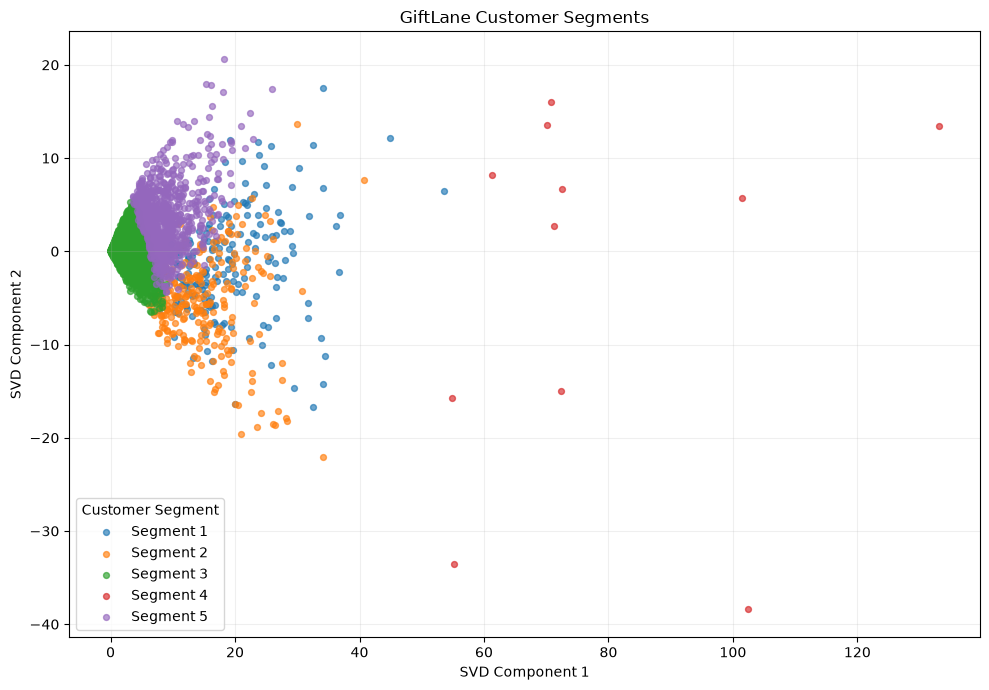

In [62]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Use the first two SVD dimensions for visualization
customer_map = customer_factors[:, :2]

# Cluster the full 200-dimensional customer representations
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
cluster_labels = kmeans.fit_predict(customer_factors)

# Store coordinates and anonymous segment labels only
customer_segments = pd.DataFrame({
    "Component 1": customer_map[:, 0],
    "Component 2": customer_map[:, 1],
    "Segment": cluster_labels
})

print("Customers mapped:", len(customer_segments))
print("Number of segments:", customer_segments["Segment"].nunique())
print("\nCustomers per segment:")
display(
    customer_segments["Segment"]
    .value_counts()
    .sort_index()
    .rename("Customer Count")
    .to_frame()
)

# Plot without customer IDs
plt.figure(figsize=(10, 7))

for segment in sorted(customer_segments["Segment"].unique()):
    subset = customer_segments[
        customer_segments["Segment"] == segment
    ]
    plt.scatter(
        subset["Component 1"],
        subset["Component 2"],
        label=f"Segment {segment + 1}",
        alpha=0.65,
        s=18
    )

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("GiftLane Customer Segments")
plt.legend(title="Customer Segment")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [63]:
# ML6: Profile each customer segment using training data

# Match each training customer to their assigned segment.
customer_segment_map = pd.DataFrame({
    "Customer ID": customers,
    "Segment": cluster_labels
})

# Attach segment labels to training transactions.
profile_data = df_train.copy()
profile_data["StockCode"] = profile_data["StockCode"].astype(str)

profile_data = profile_data.merge(
    customer_segment_map,
    on="Customer ID",
    how="inner"
)

# Keep only products included in the customer-product matrix.
profile_data = profile_data[
    profile_data["StockCode"].isin(products)
].copy()

# Top products in each segment by total quantity purchased.
product_profiles = (
    profile_data.groupby(["Segment", "StockCode", "Description"])["Quantity"]
    .sum()
    .reset_index()
    .sort_values(["Segment", "Quantity"], ascending=[True, False])
)

print("TOP 5 PRODUCTS PER SEGMENT")
for segment in sorted(profile_data["Segment"].unique()):
    print(f"\nSegment {segment + 1}")
    display(
        product_profiles[product_profiles["Segment"] == segment]
        [["StockCode", "Description", "Quantity"]]
        .head(5)
        .reset_index(drop=True)
    )

# Top countries in each segment, measured by distinct customers.
country_profiles = (
    profile_data[["Segment", "Customer ID", "Country"]]
    .drop_duplicates()
    .groupby(["Segment", "Country"])["Customer ID"]
    .nunique()
    .reset_index(name="Customer Count")
    .sort_values(
        ["Segment", "Customer Count"],
        ascending=[True, False]
    )
)

print("\nTOP 5 COUNTRIES PER SEGMENT")
for segment in sorted(profile_data["Segment"].unique()):
    print(f"\nSegment {segment + 1}")
    display(
        country_profiles[country_profiles["Segment"] == segment]
        [["Country", "Customer Count"]]
        .head(5)
        .reset_index(drop=True)
    )

TOP 5 PRODUCTS PER SEGMENT

Segment 1


,StockCode,Description,Quantity
0,85099B,JUMBO BAG RED RETROSPOT,36161
1,17003,BROCADE RING PURSE,25145
2,85099F,JUMBO BAG STRAWBERRY,20598
3,85099C,JUMBO BAG BAROQUE BLACK WHITE,16583
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,15663



Segment 2


,StockCode,Description,Quantity
0,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,27739
1,17003,BROCADE RING PURSE,22122
2,22492,MINI PAINT SET VINTAGE,16356
3,84879,ASSORTED COLOUR BIRD ORNAMENT,12322
4,22616,PACK OF 12 LONDON TISSUES,10846



Segment 3


...

,Country,Customer Count
0,United Kingdom,3891
1,Germany,67
2,France,63
3,Spain,32
4,Belgium,20



Segment 4


,Country,Customer Count
0,United Kingdom,7
1,EIRE,2
2,Australia,1
3,Netherlands,1



Segment 5


,Country,Customer Count
0,United Kingdom,739
1,Austria,3
2,Cyprus,3
3,Channel Islands,2
4,France,2


### ML7: Sensitivity Analysis

**Objective:** Evaluate how different purchase-value representations affect the recommendation model's Hit Rate@10.

Three purchase representations are compared:
- **Quantity:** Uses the total quantity purchased for each customer-product pair.
- **Binary (1/0):** Records whether a customer purchased a product.
- **Log Quantity:** Applies `log(1 + quantity)` to reduce the influence of large purchase quantities.

The Truncated SVD model is fitted separately for each representation using 200 components. All three models are evaluated using the same held-out test targets and Hit Rate@10 metric.

**Evaluation:** The representation with the highest Hit Rate@10 provides the best recommendation coverage among the three tested approaches. Model fitting time and evaluation time are also recorded.

**Conclusion:** The final conclusion will be based on the measured hit rates and runtimes. This comparison helps determine whether purchase quantity, purchase occurrence, or log-transformed quantity is the most suitable input representation for GiftLane's recommendation system.

In [64]:

# ML7: Sensitivity analysis — purchase value representation

import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.decomposition import TruncatedSVD

# Use the existing customer and product index mappings.
customer_to_idx = {c: i for i, c in enumerate(customers)}

# Keep only training transactions represented in the existing matrix.
ml7_train = df_train[
    df_train["Customer ID"].isin(customer_to_idx)
    & df_train["StockCode"].astype(str).isin(products)
].copy()

ml7_train["StockCode"] = ml7_train["StockCode"].astype(str)

# Aggregate purchases first so that binary and log values are
# calculated per customer-product pair, not per invoice line.
purchase_totals = (
    ml7_train.groupby(["Customer ID", "StockCode"])["Quantity"]
    .sum()
    .reset_index()
)

purchase_totals = purchase_totals[purchase_totals["Quantity"] > 0].copy()

purchase_totals["Customer Index"] = (
    purchase_totals["Customer ID"].map(customer_to_idx)
)
purchase_totals["Product Index"] = (
    purchase_totals["StockCode"].map(product_to_idx)
)

purchase_totals = purchase_totals.dropna(
    subset=["Customer Index", "Product Index"]
)

purchase_totals["Customer Index"] = (
    purchase_totals["Customer Index"].astype(int)
)
purchase_totals["Product Index"] = (
    purchase_totals["Product Index"].astype(int)
)

# Compare three purchase representations.
purchase_modes = {
    "Quantity": purchase_totals["Quantity"].to_numpy(dtype=float),
    "Binary (1/0)": np.ones(len(purchase_totals), dtype=float),
    "Log Quantity": np.log1p(
        purchase_totals["Quantity"].to_numpy(dtype=float)
    )
}

ml7_results = []

for mode, values in purchase_modes.items():

    A_mode = sp.csr_matrix(
        (
            values,
            (
                purchase_totals["Customer Index"].to_numpy(),
                purchase_totals["Product Index"].to_numpy()
            )
        ),
        shape=(len(customers), len(products))
    )

    # Refit SVD on the alternative training matrix.
    start = time.perf_counter()

    svd_mode = TruncatedSVD(
        n_components=200,
        random_state=42
    )
    customer_factors_mode = svd_mode.fit_transform(A_mode)
    product_factors_mode = svd_mode.components_

    fit_seconds = time.perf_counter() - start

    # Score customer-product pairs and evaluate on the same held-out targets.
    hits = 0
    evaluation_start = time.perf_counter()

    for customer_idx, target_products in target_by_customer.items():

        scores = (
            customer_factors_mode[customer_idx]
            @ product_factors_mode
        )

        # Exclude products purchased in this mode's training matrix.
        seen = A_mode[customer_idx].indices
        scores[seen] = -np.inf

        recommended = np.argsort(-scores)[:10]

        if set(recommended) & target_products:
            hits += 1

    evaluation_seconds = time.perf_counter() - evaluation_start

    ml7_results.append({
        "Purchase Representation": mode,
        "Components": 200,
        "Customers Evaluated": len(target_by_customer),
        "Customers with a Hit": hits,
        "Hit Rate@10": hits / len(target_by_customer),
        "SVD Fit Time (seconds)": fit_seconds,
        "Evaluation Time (seconds)": evaluation_seconds
    })

ml7_results_df = pd.DataFrame(ml7_results)

print("ML7: SENSITIVITY ANALYSIS")
print("Higher Hit Rate@10 indicates better held-out recommendation coverage.")
display(ml7_results_df.round(4))

best_mode = ml7_results_df.loc[
    ml7_results_df["Hit Rate@10"].idxmax()
]

print("\nBest representation by Hit Rate@10:")
print(best_mode["Purchase Representation"])
print(f"Hit Rate@10: {best_mode['Hit Rate@10']:.2%}")


ML7: SENSITIVITY ANALYSIS
Higher Hit Rate@10 indicates better held-out recommendation coverage.


,Purchase Representation,Components,Customers Evaluated,Customers with a Hit,Hit Rate@10,SVD Fit Time (seconds),Evaluation Time (seconds)
0,Quantity,200,1913,488,0.2551,2.4550,1.5321
1,Binary (1/0),200,1913,755,0.3947,2.1190,1.8918
2,Log Quantity,200,1913,761,0.3978,2.8291,0.7051



Best representation by Hit Rate@10:
Log Quantity
Hit Rate@10: 39.78%


### ML7: Sensitivity Analysis — Results and Conclusion

The sensitivity analysis evaluated three purchase-value representations using Truncated SVD with 200 components. All models were evaluated on the same 1,913 eligible customers and held-out test targets using Hit Rate@10.

The Quantity representation achieved a Hit Rate@10 of 25.51%, while the Binary (1/0) representation achieved 39.47%. The Log Quantity representation achieved the highest Hit Rate@10 of 39.78%, corresponding to 761 customers with at least one relevant held-out product in their top 10 recommendations.

These results indicate that using raw purchase quantities reduces recommendation performance compared with binary and log-transformed values. Log Quantity performs slightly better than Binary, suggesting that reducing the influence of large purchase quantities can improve recommendation quality.

The Log Quantity model required 2.8291 seconds to fit and 0.7051 seconds to evaluate, while the Binary model required 2.1190 seconds to fit and 1.8918 seconds to evaluate. These timings represent the measured operations only, not the complete nightly pipeline.

**Conclusion:** Log Quantity is the preferred representation among the three tested methods because it achieved the highest Hit Rate@10. However, its improvement over Binary was small, so further testing would be useful before making a final production decision.